In [ ]:
import numpy as np
import mbtr.utils as ut
from scipy.linalg import hankel
from scipy.stats import expon
import matplotlib.pyplot as plt
from mbtr.mbtr import MBT
from mbtr.utils import set_figure
from mbtr import LOSS_MAP
from CopulaLoss import CopulaLikelihood

LOSS_MAP['copula'] = CopulaLikelihood # this line has to be added for the MBT class to recognize the CopulaLikelihood subclass as a type of loss

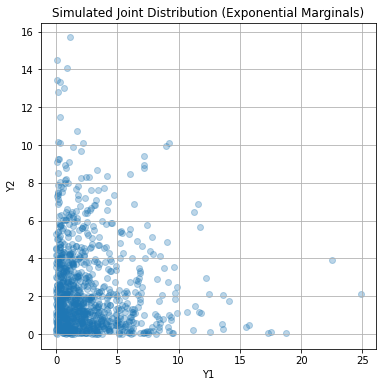

In [ ]:
# Set seed for reproducibility
np.random.seed(42)

# Number of samples
n = 1000000

# Step 1: Generate uniform covariates X1 and X2
X1 = np.random.uniform(0, 1, n)
X2 = np.random.uniform(0, 1, n)

# Step 2: Define functions for dependence and marginal parameters
def theta_func(x1, x2):
    # Map to [-1, 1]
    return np.tanh(2 * x1 - x2)

def mean1_func(x1, x2):
    # Mean must be >0 for exponential
    return 1.0 + 2.0 * x1 + np.abs(np.sin(2 * np.pi * x2))

def mean2_func(x1, x2):
    return 1.0 + 1.5 * x2 + np.abs(np.cos(2 * np.pi * x1))

# Step 3: Sample from FGM copula

# Sample independent U, V from Uniform(0, 1)
U = np.random.uniform(0, 1, n)
V_indep = np.random.uniform(0, 1, n)

# Compute theta values
theta_vals = theta_func(X1, X2)

# Apply FGM copula transformation
V = V_indep + theta_vals * V_indep * (1 - V_indep) * (1 - 2 * U)

# Clip to [0,1] to ensure valid inputs to inverse CDF
U = np.clip(U, 1e-10, 1 - 1e-10)
V = np.clip(V, 1e-10, 1 - 1e-10)

# Step 4: Transform to Exponential marginals

mean1_vals = mean1_func(X1, X2)
mean2_vals = mean2_func(X1, X2)

# In scipy, expon.ppf takes a "scale" parameter = mean
Y1 = expon.ppf(U, loc=0, scale=mean1_vals)
Y2 = expon.ppf(V, loc=0, scale=mean2_vals)

# ✅ Done! Y1 and Y2 are sampled from exponential marginals linked by FGM copula.

# Optional: plot a sample
plt.figure(figsize=(6, 6))
plt.scatter(Y1[:1000], Y2[:1000], alpha=0.3)
plt.title("Simulated Joint Distribution (Exponential Marginals)")
plt.xlabel("Y1")
plt.ylabel("Y2")
plt.grid(True)
plt.show()


  0%|          | 0/10 [00:00<?, ?it/s]

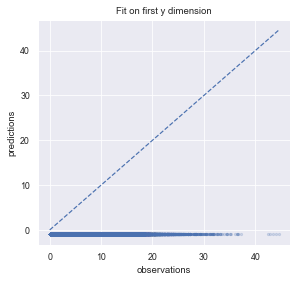

100%|██████████| 10/10 [01:34<00:00,  9.48s/it]

#---------------- Model fitted in 1.58e+00 min ----------------


In [ ]:
x = np.vstack((X1, X2)).T
y = np.vstack((Y1, Y2)).T

m = MBT(loss_type = "copula", n_boosts = 10, min_leaf = 300, refit=False).fit(x, y, do_plot=False)

In [ ]:
param_prediction = m.predict(x)

0.37902448780846576

In [14]:
print(np.exp(param_prediction[0,0]))
print(np.exp(param_prediction[0,1]))
print((2/np.pi)*np.arctan(param_prediction[0,2]))

0.37902448780846576
0.41040078223116605
-0.20019185550748742
